# Phase 5b: FD003 confirmation and interval calibration

**Goal:** make the Phase 5 conclusions more reliable using only the original NASA data: test the frozen FD001 recipe on FD003 (100 new test engines, a second fault mode), settle LSTM vs XGBoost on 200 engines, and check a better interval rule on data that played no part in choosing it.

Training and scoring: `models/run_fd003.py`. Rule choice: `models/calibration.py`. Checks: `python -m models.verify_fd003`. Metrics document: `docs/MODEL_METRICS_PHASE5B.md`.

## Concepts in plain words

- **Confirmation set:** data kept completely unseen until every decision is made. FD001's test set was already used, so FD003 plays this role.
- **Pre-registration:** writing down the tests and the decision rule (here, in a dated git commit) before seeing the data, so results cannot steer the choices.
- **Frozen recipe:** the same sensors, features and model settings as FD001; only what the procedure itself learns (scaler, epochs, trees, interval factors) is learned again on FD003's own training and validation engines.
- **Pooling with stratified resampling:** combine both test sets (200 engines) and resample engines *within* each dataset, so every bootstrap sample keeps 100 engines from each.
- **Fault modes:** FD001 engines degrade in one way (high-pressure compressor); FD003 engines in one of two ways (compressor or fan). Some sensors move in opposite directions under the two faults.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid")
res = json.loads((ROOT / "models/results_phase5b.json").read_text())
rule = json.loads((ROOT / "models/calibration_rule.json").read_text())
preds = pd.read_csv(ROOT / "models/predictions_phase5b.csv", float_precision="round_trip")
print("environment:", res["environment"])

environment: {'os': 'win32', 'platform': 'Windows-11-10.0.26300-SP0', 'python': '3.14.7', 'torch': '2.14.1+cpu', 'xgboost': '3.4.1', 'threads': 1, 'deterministic': True}


## 5b.1 Interval rule, chosen on FD001 validation only

In [2]:
pd.DataFrame({k: {"rule": c["rule"], "test-like": c["loeo_coverage_testlike"], "near failure": c["loeo_coverage_near_failure"],
                  "width (test-like)": c["mean_width_testlike"]} for k, c in rule["candidates"].items()}).T

,rule,test-like,near failure,width (test-like)
A,one k from all validation readings (Phase 5),0.858423,0.833333,31.917132
B,one k from test-like readings,0.897133,0.861765,36.060007
C,one k from readings with TRUE RUL <= 50 (not u...,0.932616,0.892157,41.724181
E,"two k from test-like readings, switched on PRE...",0.892832,0.886275,35.003872


## 5b.2 FD003 results (scored once)

In [3]:
pd.DataFrame({n: {"val RMSE": m["val_rmse"], "test RMSE": m["rmse"], "95% interval": f"{m['rmse_ci95'][0]:.1f}-{m['rmse_ci95'][1]:.1f}",
                  "PHM08": m["phm"], "near-failure MAE": m["near_failure_mae"], "late share": m["late_share"]}
              for n, m in res["models"].items()}).T

,val RMSE,test RMSE,95% interval,PHM08,near-failure MAE,late share
Fleet average,41.03292,43.700011,38.7-48.2,57686.921642,69.005273,0.65
Age only (cycle count),31.115538,33.937672,30.0-37.5,8662.160961,46.790728,0.61
"Ridge, all 168 features",15.973907,17.099763,15.1-18.9,508.816836,12.207286,0.56
"XGBoost, all 168 features",12.104068,15.497012,12.7-18.0,542.928973,4.843621,0.58
LSTM,10.114729,12.656308,10.0-15.0,324.061219,2.375251,0.5
CNN,12.380141,13.070713,10.9-15.2,308.406537,4.378806,0.43


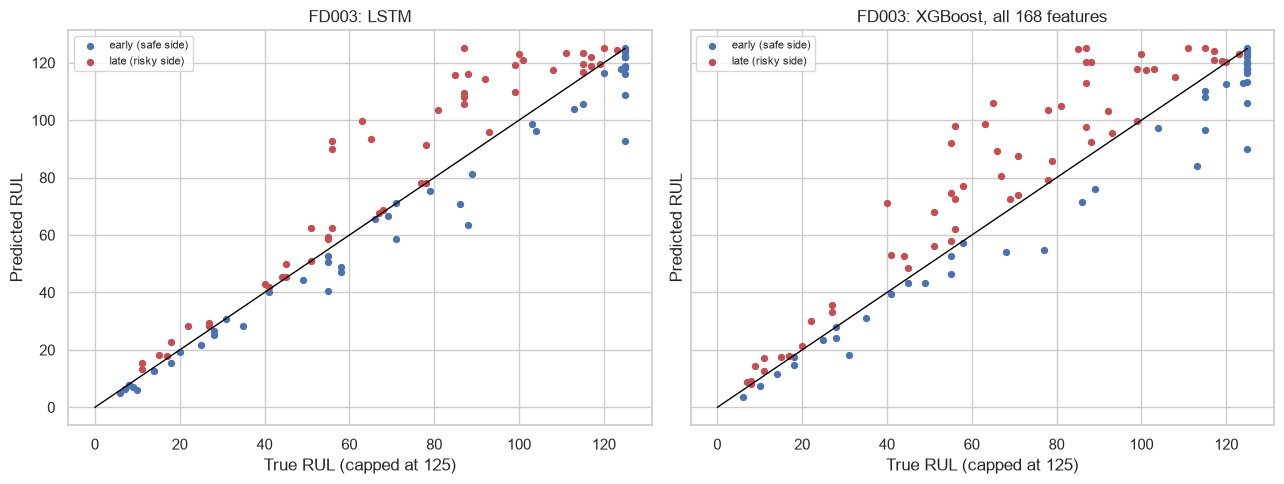

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, m in zip(axes, ["LSTM", "XGBoost, all 168 features"]):
    late = preds[m] > preds.RUL
    ax.scatter(preds.RUL[~late], preds[m][~late], s=18, label="early (safe side)", color="#4C72B0")
    ax.scatter(preds.RUL[late], preds[m][late], s=18, label="late (risky side)", color="#C44E52")
    ax.plot([0, 125], [0, 125], color="black", linewidth=1)
    ax.set(title=f"FD003: {m}", xlabel="True RUL (capped at 125)", ylabel="Predicted RUL")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fd003_pred_vs_true.png", dpi=150, bbox_inches="tight")

## 5b.3 Pre-registered tests (one Holm family) and pooled scores

In [5]:
pd.DataFrame({k: {"gap A - B": t["diff"], "95% interval": f"{t['ci'][0]:+.2f} to {t['ci'][1]:+.2f}", "Holm p": t["p_holm"],
                  "significant": t["significant"]} for k, t in res["tests"].items()}).T

,gap A - B,95% interval,Holm p,significant
"H1 LSTM vs XGBoost, RMSE, FD001+FD003",-2.306766,-4.05 to -0.76,0.007,True
"H2 LSTM vs XGBoost, near-failure MAE, FD001+FD003",-1.839366,-3.23 to -0.57,0.007,True
"H3 LSTM vs XGBoost, RMSE, FD003",-2.840704,-4.77 to -1.03,0.01,True
"H4 LSTM vs XGBoost, PHM08, FD003",-218.867755,-381.81 to -66.15,0.012,True
"H5 LSTM vs XGBoost, near-failure MAE, FD003",-2.46837,-4.89 to -0.57,0.015,True
"H6 CNN vs XGBoost, RMSE, FD003",-2.426298,-4.39 to -0.59,0.015,True
"H7 CNN vs XGBoost, PHM08, FD003",-234.522436,-403.85 to -89.68,0.004,True
"H8 CNN vs XGBoost, near-failure MAE, FD003",-0.464815,-2.76 to +1.34,0.7,False


In [6]:
pd.DataFrame(res["pooled_fd001_fd003"]).T

,rmse,near_failure_mae
LSTM,12.982731,2.761859
CNN,13.486249,4.503964
"XGBoost, all 168 features",15.289497,4.601225


## 5b.4 Intervals on FD003

k_near                                     3.676
k_far                                      4.101
test_coverage                              0.860
test_coverage_near_failure                 1.000
test_mean_width                           35.764
phase5_rule_k                              3.437
phase5_rule_test_coverage                  0.820
phase5_rule_test_coverage_near_failure     1.000
raw_test_coverage                          0.620
dtype: float64

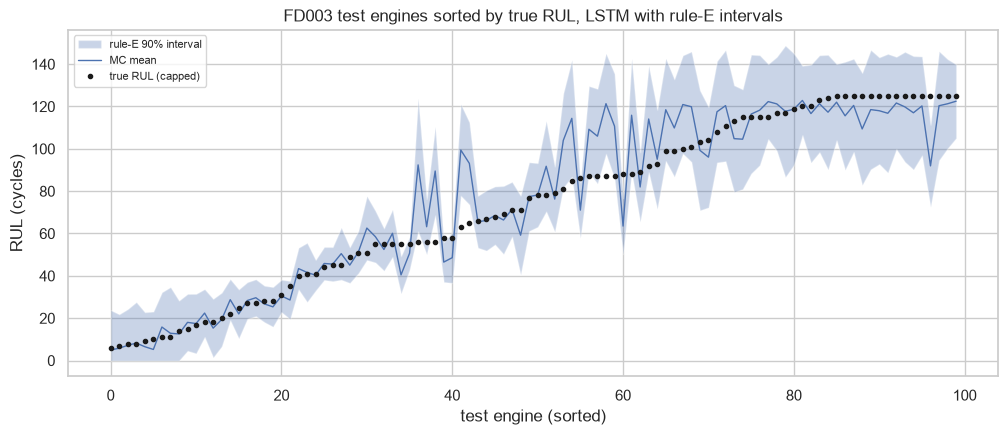

In [7]:
o = preds.sort_values("RUL").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(o.index, o["MC 90% low (rule E)"], o["MC 90% high (rule E)"], alpha=0.3, label="rule-E 90% interval")
ax.plot(o.index, o["MC mean"], color="#4C72B0", linewidth=1, label="MC mean")
ax.plot(o.index, o.RUL, "k.", label="true RUL (capped)")
ax.set(title="FD003 test engines sorted by true RUL, LSTM with rule-E intervals", xlabel="test engine (sorted)", ylabel="RUL (cycles)")
ax.legend(fontsize=8)
fig.savefig(FIG / "fd003_intervals.png", dpi=150, bbox_inches="tight")
pd.Series({k: v for k, v in res["mc_dropout"]["FD003"].items()}).round(3)

## Findings (generated from the results; every claim is asserted)

1. **Interval rule, fixed before FD003.** On FD001 validation (leave-engines-out), the Phase 5 rule covered 85.8% of test-like and 83.3% of near-failure readings at a nominal 90%. Rule E (two factors, switched on the *predicted* RUL) covers 89.3% and 88.6%. It was committed before any FD003 model was trained.
2. **FD003 results.** Test RMSE: LSTM 12.66, CNN 13.07, XGBoost, all 168 features 15.50; the same order as on FD001. Best on FD003: **LSTM**. All three learned models beat the fleet average (43.70) and the age-only rule (33.94), so the FD001 recipe transfers to a dataset with a second fault mode without re-tuning.
3. **Verdict on 200 engines.** **The LSTM replaces XGBoost as the published model.** With 200 test engines its RMSE gap is -2.31 (interval -4.05 to -0.76, Holm p 0.007), and it is at least as accurate near failure (2.76 vs 4.60 cycles). Doubling the test evidence turned a suggestive FD001 gap into a confirmed one. Tests significant after Holm: H1 LSTM vs XGBoost, RMSE, FD001+FD003; H2 LSTM vs XGBoost, near-failure MAE, FD001+FD003; H3 LSTM vs XGBoost, RMSE, FD003; H4 LSTM vs XGBoost, PHM08, FD003; H5 LSTM vs XGBoost, near-failure MAE, FD003; H6 CNN vs XGBoost, RMSE, FD003; H7 CNN vs XGBoost, PHM08, FD003.
4. **Intervals on fresh data.** FD003 test coverage with rule E: **86%** (100% of the 29 engines near failure, above target: conservative where alerts matter); the Phase 5 rule would have given 82%, raw MC percentiles 62%. Overall coverage is within 5 points of the nominal 90%. On FD001 (post hoc, already seen) rule E gives 89% (91% near failure), against 82% for the Phase 5 rule.
5. **What this means for Phase 6.** The published model for alerts is **LSTM**; alerts should use the lower edge of the rule-E interval, whose coverage has now been checked on data that played no part in choosing it.

## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Chose an interval rule on FD001 validation and committed it first | FD001's test coverage had been seen; re-tuning on it would be fitting the test set | Rule E fixes the under-coverage where it matters, using only what is known at prediction time | Phase 6 alerts use rule-E intervals |
| 2 | Made the loaders dataset-aware with per-dataset scaler and split files | FD003 must get its own training-only scaler, like FD001 | The FD001 path is unchanged (all earlier verifiers still pass) | Any NASA subset can be added the same way |
| 3 | Froze every FD001 setting and wrote the 8 tests before running | A confirmation is only honest if nothing is chosen after seeing it | The commit history proves the order | Later phases keep the same "decide, commit, then test" order |
| 4 | Ran all models on FD003 (5 seeds each) | 100 new test engines and a second fault mode | The same order as on FD001; best: LSTM | Generalisation is measured, not assumed |
| 5 | Pooled FD001 + FD003 (engines resampled within each dataset) | 200 engines give much tighter intervals than 100 | The LSTM-vs-XGBoost question now has a confirmed answer: LSTM | Phase 6 builds on LSTM |
| 6 | Independent verifier and CI | Every published number must recompute with separate code | Scaler, windows, metrics, intervals, tests and verdict all recompute | The confirmation is part of every CI run |
